# Molecular grammars of the yeast IDRome

The published **GIN** resource partitions the *human* IDRome into 30 clusters of
shared molecular grammar. This notebook does the equivalent for
*Saccharomyces cerevisiae*, from scratch:

1. predict the disordered regions of every yeast protein,
2. build a **yeast** compositional background,
3. compute a NARDINI+ vector for every IDR,
4. cluster those vectors into yeast-native grammars,
5. look at which proteins actually sit in each cluster, and
6. ask how the yeast grammars relate to the published human ones.

**Why not just use the published human clusters?** Because they are defined in
human NARDINI+ z-score space. A yeast IDR scored against them gets a label, but
the label describes which *human* grammar it most resembles, and the compositional
half of the vector is z-scored against a population it does not belong to. For a
non-human proteome the right move is to derive the grammars from that proteome —
which is what `build_gin_reference()` is for.

The whole notebook runs in about five minutes on a laptop.

In [1]:
import collections
import re

import numpy as np
import protfasta
import metapredict as meta
from matplotlib import pyplot as plt

from sparrow.nardini import (
    assign_gin_clusters,
    build_background,
    build_gin_reference,
    compare_gin_references,
    nardini_vectors,
)
from sparrow.nardini.gin import GINReference

%matplotlib inline

## 1. The proteome

The reference proteome for *S. cerevisiae* S288c (UniProt UP000002311), downloaded
as FASTA. Keys are the full UniProt headers, which carry both the accession and the
gene name — we keep the gene names so the clusters can be read biologically later.

In [2]:
proteome = protfasta.read_fasta("uniprotkb_proteome_UP000002311_2026_07_27.fasta")
print(f"{len(proteome)} proteins in the yeast reference proteome")

# sp|P32468|CDC12_YEAST Cell division control protein 12 ... GN=CDC12 PE=1 SV=2
gene_of, protein_name_of = {}, {}
for header in proteome:
    accession = header.split("|")[1]
    gene = re.search(r"GN=(\S+)", header)
    name = re.search(r"^[^ ]+ (.*?) OS=", header)
    gene_of[accession] = gene.group(1) if gene else accession
    protein_name_of[accession] = name.group(1) if name else ""

example = list(proteome)[1]
print("\nexample header:", example[:80], "...")
print("  accession:", example.split("|")[1], "| gene:", gene_of[example.split("|")[1]])

6067 proteins in the yeast reference proteome

example header: sp|D6VTK4|STE2_YEAST Pheromone alpha factor receptor OS=Saccharomyces cerevisiae ...
  accession: D6VTK4 | gene: STE2


## 2. Finding the IDRs

`metapredict` predicts per-residue disorder and, with `return_domains=True`, hands
back contiguous disordered regions. Every one of those becomes an entry in our IDR
set, named `<accession>_IDR_<n>`.

In [3]:
yeast_proteome = meta.predict_disorder(proteome, return_domains=True)

yeast_idrs = {}
idr_source = {}          # IDR name -> accession, so we can get back to the protein
for header in yeast_proteome:
    accession = header.split("|")[1]
    for index, domain in enumerate(yeast_proteome[header].disordered_domains):
        name = f"{accession}_IDR_{index}"
        yeast_idrs[name] = domain
        idr_source[name] = accession

lengths = np.array([len(s) for s in yeast_idrs.values()])
print(f"found {len(yeast_idrs)} IDRs across {len(proteome)} proteins")
print(f"  length: median {int(np.median(lengths))}, "
      f"mean {lengths.mean():.0f}, range {lengths.min()}-{lengths.max()}")
print(f"  proteins with at least one IDR: "
      f"{len({idr_source[n] for n in yeast_idrs})}")

found 8199 IDRs across 6067 proteins
  length: median 55, mean 98, range 13-1609
  proteins with at least one IDR: 4775


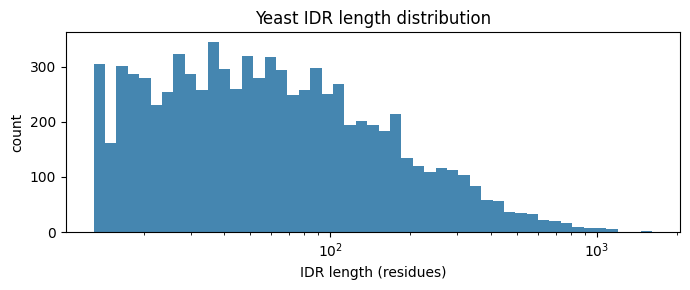

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(lengths, bins=np.logspace(np.log10(max(lengths.min(), 1)), np.log10(lengths.max()), 50),
        color="#2471a3", alpha=0.85)
ax.set_xscale("log")
ax.set_xlabel("IDR length (residues)")
ax.set_ylabel("count")
ax.set_title("Yeast IDR length distribution")
plt.tight_layout()
plt.show()

Note that this keeps **every** predicted IDR, including very short ones. The
published IDRome analyses use a minimum length (30 residues is common), and short
IDRs give noisy compositional features. Filtering is a one-liner if you want it:

```python
yeast_idrs = {k: v for k, v in yeast_idrs.items() if len(v) >= 30}
```

Anything shorter than the patterning window (5 residues) cannot be scored at all
and would raise — use `nardini_proteins(..., on_error='skip')` if you would rather
drop those than filter up front.

## 3. A yeast compositional background

The compositional half of a NARDINI+ vector is z-scored against a reference set of
IDRs. Using the yeast IDRome as its own reference is what makes the resulting
z-scores mean "unusual **for yeast**".

In [5]:
background = build_background(yeast_idrs)
print(background)
print(f"  built from {background.num_sequences} IDRs")
print(f"  features with no variation: {background.metadata['num_degenerate_features']} of 54")

NardiniBackground|54 features|n=8199
  built from 8199 IDRs
  features with no variation: 0 of 54


## 4. NARDINI+ vectors for every IDR

Each vector is 90 numbers: 36 **patterning** z-scores against scrambles of that
same sequence, and 54 **compositional** z-scores against the background above.

The patterning half is the expensive part — 10,000 scrambles per IDR — so this runs
across processes. `n_processes` is the argument (not `num_workers`); the result is
bit-identical however the work is divided, because each sequence's seed derives
from its own text rather than its position in the batch.

In [6]:
vectors = nardini_vectors(
    yeast_idrs,
    background=background,
    num_scrambles=10000,
    seed=42,
    n_processes=16,
    show_progress=True,
)
print(vectors)

NARDINI:   0%|          | 0/65 [00:00<?, ?it/s]

NARDINI:   2%|▏         | 1/65 [00:53<56:46, 53.23s/it]

NARDINI:   3%|▎         | 2/65 [00:55<24:10, 23.02s/it]

NARDINI:   5%|▍         | 3/65 [00:55<13:02, 12.62s/it]

NARDINI:   6%|▌         | 4/65 [00:55<07:56,  7.81s/it]

...

NARDINI:  97%|█████████▋| 63/65 [04:10<00:01,  1.26it/s]

NARDINI:  98%|█████████▊| 64/65 [04:10<00:00,  1.67it/s]

NARDINI: 100%|██████████| 65/65 [04:11<00:00,  1.37it/s]

NARDINI: 100%|██████████| 65/65 [04:11<00:00,  3.87s/it]

NardiniResult|8199 sequences|90 features


## 5. Deriving yeast-native grammars

`build_gin_reference()` runs the same procedure the published GIN analysis used:
clip the z-scores to ±3, then k-means. We ask for `k=30` to match the human
analysis, though there is nothing special about 30 for yeast — it is a choice, and
worth revisiting for your own question.

Cluster **numbers** are arbitrary (k-means has no canonical ordering); sparrow sorts
them largest-first so at least they are stable within a run. The descriptions are
generated from each centroid's most extreme features, not human-authored prose.

In [7]:
reference = build_gin_reference(vectors, k=30, seed=0)
print(reference, "| backend:", reference.backend)
print(f"  clustered {reference.metadata['num_sequences']} IDRs into "
      f"{reference.metadata['k']} grammars")

GINReference|30 clusters|90 features | backend: nardini
  clustered 8199 IDRs into 30 grammars


Save it. The vectors behind this took minutes, and re-clustering with a different
seed gives different — equally valid — centroids, so persisting the reference is
what keeps a set of results comparable.

In [8]:
reference.save("yeast_gin_clusters.npz")

# reload to prove it round-trips
print(GINReference.load("yeast_gin_clusters.npz"))

GINReference|30 clusters|90 features


## 6. The yeast grammars

Assigning the same IDRs back against the reference tells us which cluster each one
landed in. (`reference.num_idrs` already records the sizes from the clustering
itself; assigning is what gives us the *membership*.)

In [9]:
assignment = assign_gin_clusters(vectors, reference=reference)

members = collections.defaultdict(list)
for record in assignment.records():
    members[record["cluster"]].append(record["name"])

print(f"{'cl':>3s}  {'n':>5s}  grammar")
for cluster in reference.clusters:
    print(f"{cluster:3d}  {reference.num_idrs[cluster]:5d}  {reference.describe(cluster)}")

 cl      n  grammar
  0    482  low Iso point, well-mixed hyd-neg, low NCPR
  1    447  low NCPR, low Iso point, high Frac D+E
  2    427  low Frac Chain Expanding, high Frac Polar, low FCR
  3    423  high Frac Polar, high Frac S, low Frac Aliphatic
  4    412  blocky pos-neg, blocky neg-neg, well-mixed hyd-hyd
  5    411  blocky pol-neg, blocky pol-pol, blocky pol-hyd
  6    392  high Iso point, high Frac R, high NCPR
  7    377  high Frac K, high Frac K+R, high Iso point
  8    347  high Frac Aromatic, high Frac F, low Disorder Promoting
  9    336  blocky pol-pos, blocky pol-pol, blocky pol-hyd
 10    332  blocky pos-neg, blocky pol-pos, blocky pol-neg
 11    300  high Frac E, high Frac Chain Expanding, high Frac D+E
 12    282  blocky pos-neg, blocky pos-pos, blocky hyd-pos
 13    280  high Frac S, high Frac Polar, S patches
 14    255  blocky hyd-pos, blocky pos-pos, blocky hyd-hyd
 15    247  high Frac P, high PPII, low FCR
 16    231  high Hydrophobicity, high Frac Aliphatic, l

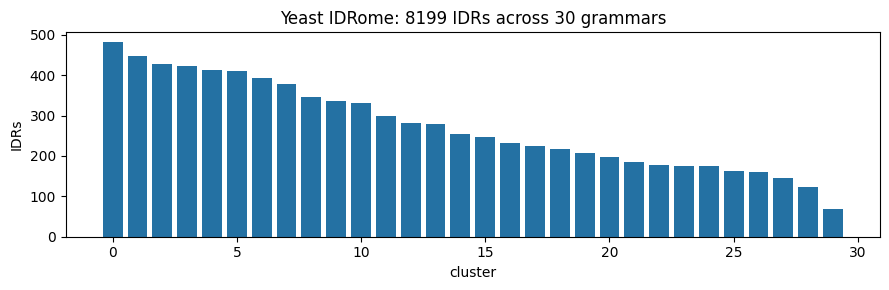

In [10]:
sizes = [reference.num_idrs[c] for c in reference.clusters]
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(sizes)), sizes, color="#2471a3")
ax.set_xlabel("cluster")
ax.set_ylabel("IDRs")
ax.set_title(f"Yeast IDRome: {len(yeast_idrs)} IDRs across {len(sizes)} grammars")
plt.tight_layout()
plt.show()

## 7. What is actually in a cluster?

A grammar described as "high Frac Q, Q patches" is only interesting if you can see
*which* proteins it contains. The records carry IDR names; `idr_source` and
`gene_of` take us from those back to gene names, and `vectors` carries the
sequences.

In [11]:
sequence_of = dict(zip(vectors.names, vectors.sequences))

def show_cluster(cluster, n=8, width=68):
    """Print a cluster's grammar, size, and its first few member IDRs."""
    names = members[cluster]
    print(f"cluster {cluster}: {reference.describe(cluster)}")
    print(f"  {len(names)} IDRs\n")
    for name in names[:n]:
        gene = gene_of.get(idr_source[name], "?")
        sequence = sequence_of[name]
        shown = sequence[:width] + ("..." if len(sequence) > width else "")
        print(f"  {gene:<10s} {name:<18s} L={len(sequence):<5d} {shown}")
    if len(names) > n:
        print(f"  ... and {len(names) - n} more")

### The largest cluster

In [12]:
show_cluster(0)

cluster 0: low Iso point, well-mixed hyd-neg, low NCPR
  482 IDRs

  IPP1       P00817_IDR_0       L=42    VTLPDTPTYSKAASDAIPPASPKADAPIDKSIDKWFFISGSV
  GCN4       P03069_IDR_0       L=235   MSEYQPSLFALNPMGFSPLDGSKSTNENVSASTSTAKPMVGQLIFDKFIKTEEDPIIKQDTPSNLDFD...
  RPO31      P04051_IDR_0       L=56    MKEVVVSETPKRIKGLEFSALSAADIVAQSEVEVSTRDLFDLEKDRAPKANGALDP
  PAB1       P04147_IDR_0       L=43    MADITDKTAEQLENLNIQDDQKQAATGSESQSVENSSASLYVG
  TPK3       P05986_IDR_0       L=71    MYVDPMNNNEIRKLSITAKTETTPDNVGQDIPVNAHSVHEECSSNTPVEINGRNSGKLKEEASAGICL...
  CDC37      P06101_IDR_1       L=45    ISSEDIHTGFDSSFMNKQKGGAKPLEATPSEALSSAAESNILNKL
  NOT3       P06102_IDR_2       L=51    PPVDTASEVRDVSVDNNNVNDQSNVTLEQQKQEISHGKQLLKQLKQGKISV
  SIR2       P06700_IDR_0       L=106   MTIPHMKYAVSKTSENKVSNTVSPTQDKDAIRKQPDDIINNDEPSHKKIKVAQPDSLRETNTTDPLGH...
  ... and 474 more


### A few clusters with distinctive grammars

Rather than pick by hand, take the clusters whose centroids are most extreme — the
ones whose grammar is most unlike the average IDR.

In [13]:
distinctive = sorted(
    reference.clusters,
    key=lambda c: np.abs(reference.centroids[c]).max(),
    reverse=True,
)[:3]

for cluster in distinctive:
    show_cluster(cluster, n=6)
    print()

cluster 18: blocky pos-neg, blocky neg-neg, blocky pol-neg
  216 IDRs

  SEM1       O94742_IDR_0       L=89    MSTDVAAAQAQSKIDLTKKKNEEINKKSLEEDDEFEDFPIDTWANGETIKSNAVTQTNIWEENWDDVE...
  TOP1       P04786_IDR_0       L=132   MTIADASKVNHELSSDDDDDVPLSQTLKKRKVASMNSASLQDEAEPYDSDEAISKISKKKTKKIKTEP...
  RAD7       P06779_IDR_0       L=140   MYRSRNRPKRGGENEVKGPNSALTQFLREEGISAENIKQKWYQRQSKKQEDATDEKKGKAEDDSFTAE...
  SNF1       P06782_IDR_1       L=188   DLKPHPEEENENNDSKKDGSSPDNDEIDDNLVNILSSTMGYEKDEIYESLESSEDTPAFNEIRDAYML...
  TOP2       P06786_IDR_1       L=256   DAEARGGNVPNKGSKTKGKGKRKLVDDEDYDPSKKNKKSTARKGKKIKLEDKNFERILLEQKLVTKSK...
  RAD3       P06839_IDR_0       L=57    RTMAQPTDPKDQEGVSVWSYEDLIKHQNSRKDQGGFIENENKEGEQDEDEDEDIEMQ
  ... and 210 more

cluster 27: Q patches, high Frac Q, blocky pol-pol
  145 IDRs

  PAB1       P04147_IDR_1       L=79    AAAAAGMPGQFMPPMFYGVMPPRGVPFNGPNPQQMNPMGGMPKNGMPPQFRNGPVYGVPPQGGFPRNA...
  SUP35      P05453_IDR_0       L=254   MSDSNQGNNQQNYQQYSQNGNQQQGNNRYQGYQAYN

### Finding the cluster for a protein you care about

The mapping runs both ways: given a gene, find its IDRs and their grammars.

In [14]:
cluster_of = {record["name"]: record["cluster"] for record in assignment.records()}

for gene in ["CDC12", "SUP35", "PAB1", "NPL3"]:
    accessions = [a for a, g in gene_of.items() if g == gene]
    for accession in accessions:
        idrs = [n for n in yeast_idrs if idr_source[n] == accession]
        for name in idrs:
            cluster = cluster_of[name]
            print(f"{gene:<7s} {name:<18s} L={len(sequence_of[name]):<5d} "
                  f"cluster {cluster:2d}: {reference.describe(cluster)}")

CDC12   P32468_IDR_0       L=18    cluster 24: high Frac A, high Frac Aliphatic, A patches
CDC12   P32468_IDR_1       L=14    cluster 11: high Frac E, high Frac Chain Expanding, high Frac D+E
CDC12   P32468_IDR_2       L=24    cluster  1: low NCPR, low Iso point, high Frac D+E
SUP35   P05453_IDR_0       L=254   cluster 27: Q patches, high Frac Q, blocky pol-pol
PAB1    P04147_IDR_0       L=43    cluster  0: low Iso point, well-mixed hyd-neg, low NCPR
PAB1    P04147_IDR_1       L=79    cluster 27: Q patches, high Frac Q, blocky pol-pol
NPL3    Q01560_IDR_0       L=133   cluster 28: P patches, high Frac P, blocky pol-pro
NPL3    Q01560_IDR_1       L=145   cluster 25: high Frac G, high Frac Polar, low PPII


## 8. Which of these labels should be trusted?

Nearest-centroid assignment never abstains — every IDR gets a cluster. Three
diagnostics say when not to believe one: `separation` (gap to the runner-up),
`n_saturated` (features pinned at the ±3 clip), and `composition_rms_z` (how far
the IDR sits from the reference population).

Here the reference population *is* the yeast IDRome, so `composition_rms_z` should
mostly be near 1 — that is a useful sanity check on the whole pipeline.

In [15]:
print(f"composition_rms_z: median {np.median(assignment.composition_rms_z):.2f}, "
      f"90th pct {np.percentile(assignment.composition_rms_z, 90):.2f}")
print(f"flagged atypical : {(~assignment.is_typical).sum()} of {len(assignment.is_typical)} "
      f"({100 * (~assignment.is_typical).mean():.1f}%)")
print(f"median separation: {np.median(assignment.separations):.2f} "
      f"(centroid spacing is {reference.separation_scale:.2f})")

composition_rms_z: median 0.76, 90th pct 1.36
flagged atypical : 330 of 8199 (4.0%)
median separation: 5.40 (centroid spacing is 15.24)


## 9. How do yeast grammars relate to the human ones?

`compare_gin_references()` pairs our centroids one-to-one against the published
human GIN centroids by solving the optimal assignment, and reports the distances.

Read the three numbers together. A mean match distance well below the published
centroid spacing means the two clusterings largely agree; comparable or above means
they do not. Check our own spacing too: a clustering that found no structure leaves
its centroids near the origin, close to everything, which produces a flatteringly
small match distance.

One caveat worth stating plainly: our vectors were z-scored against a **yeast**
background, and the human centroids live in **human** z-score space. So this
comparison is suggestive of which grammars are analogous, not a claim that the
coordinates are commensurate.

In [16]:
report = compare_gin_references(reference)

print(f"mean match distance         : {report['mean_distance']:8.2f}  (squared Euclidean)")
print(f"median                      : {report['median_distance']:8.2f}")
print(f"published centroid spacing  : {report['separation_scale']:8.2f}")
print(f"our centroid spacing        : {report['reference_separation_scale']:8.2f}")
print()
print(f"{'ours':>4s}  {'yeast grammar':44s}  {'human match':30s} {'d':>7s}")
for pair in sorted(report["pairs"], key=lambda p: p["distance"])[:10]:
    print(f"{pair['cluster']:4d}  {pair['description'][:43]:44s}  "
          f"{pair['matched_description'][:29]:30s} {pair['distance']:7.1f}")

mean match distance         :    16.38  (squared Euclidean)
median                      :     9.16
published centroid spacing  :    17.81
our centroid spacing        :    15.24

ours  yeast grammar                                 human match                          d
   0  low Iso point, well-mixed hyd-neg, low NCPR   Weak negative charge               1.8
   5  blocky pol-neg, blocky pol-pol, blocky pol-   Small negative blocks              2.7
   7  high Frac K, high Frac K+R, high Iso point    Weak positive charge               2.9
  18  blocky pos-neg, blocky neg-neg, blocky pol-   Large negative blocks with po      2.9
   9  blocky pol-pos, blocky pol-pol, blocky pol-   Blocks of polar residues           3.4
  14  blocky hyd-pos, blocky pos-pos, blocky hyd-   Blocks of positive residues        3.5
   4  blocky pos-neg, blocky neg-neg, well-mixed    Blocks of positive & negative      4.0
   2  low Frac Chain Expanding, high Frac Polar,    S patches                          4.9
  1

## Where to go from here

* **Use the reference.** `yeast_gin_clusters.npz` can be loaded with
  `GINReference.load()` and passed to `assign_gin_clusters(..., reference=...)` to
  place new yeast IDRs — a mutant, a designed construct, a set of hits — into these
  grammars.
* **Revisit `k`.** 30 was chosen to mirror the human analysis. Cluster the vectors
  at several values and look at where the structure actually is.
* **Filter the IDR set.** Repeating with a minimum length of 30 residues gives a
  cleaner, more conventional IDRome and will change the grammars.
* **Keep the vectors.** `vectors.zscores` is an `(n_IDRs, 90)` matrix — the input
  to any other analysis you want, clustering or otherwise.

### Citation

sparrow is an independent implementation. Please cite the original work:

* **NARDINI**: Cohan, M. C., Shinn, M. K., Lalmansingh, J. M. & Pappu, R. V.
  *J. Mol. Biol.* (2022).
* **GIN / NARDINI+**: Ruff, K. M. *et al.* *Cell* (2025).
* **metapredict**: Emenecker, R. J., Griffith, D. & Holehouse, A. S.
  *Biophys. J.* (2021).